# Implementando makemore

* Qué es un modelo de bigramas estadístico auto-regresivo y cómo implementamos uno?
* Los bigramas son secuencias de dos carácteres, por ejemplo `ab` o `gh`. Predecir el siguiente caracter dado el anterior caracter

## 🎯 Objetivos de este notebook

En este notebook construimos, paso a paso, un **modelo de lenguaje de bigramas** que aprende a generar nombres de ciudades.

**¿Qué significa cada palabra?**
- **Modelo de lenguaje:** un programa que aprende patrones de un texto para poder generar texto nuevo parecido.
- **Bigrama:** un par de caracteres consecutivos (ej. `ka`, `ot`). El modelo mira **un caracter** para predecir **el siguiente**.
- **Autoregresivo:** genera la salida de a un caracter por vez, y cada caracter nuevo depende del anterior.
- **Probabilístico:** en vez de dar una única respuesta, asigna una *probabilidad* a cada caracter posible y luego sortea uno.

**El plan será:**
1. Cargar y limpiar un dataset de nombres de ciudades.
2. Contar cuántas veces aparece cada bigrama.
3. Guardar esos conteos en una **matriz**.
4. Convertir los conteos en **probabilidades**.
5. **Generar** nombres nuevos sorteando caracteres según esas probabilidades.
6. **Medir** qué tan bueno es el modelo con una métrica llamada *Negative Log Likelihood* (NLL).
7. Dar el primer paso hacia el enfoque con **redes neuronales** (one-hot encoding).

> 💡 **Idea clave:** no le damos reglas al modelo ("después de la q suele venir una u"). El modelo las *descubre solo* contando lo que pasa en los datos reales.

## Explorando el dataset

In [1]:
# Abrimos el archivo de nombres de ciudades y lo leemos completo.
# .read() devuelve TODO el texto del archivo; .split('\n') lo corta en una lista,
# un nombre de ciudad por cada línea.
dataset = open('data/city_names_puny.txt', 'r').read().split('\n')
dataset  # El archivo viene en "punycode": una codificación ASCII para representar texto no-ASCII (acentos, otros alfabetos)

# Separamos los nombres que están en punycode (empiezan con 'xn--') de los que no.
puny = [x for x in dataset if 'xn--' in x]        # nombres codificados en punycode
nopuny = [x for x in dataset if 'xn--' not in x]  # nombres "normales" (ASCII simple)

In [2]:
import numpy as np  # NumPy: librería para trabajar con arrays y operaciones numéricas de forma eficiente

In [3]:
# Fijamos la "semilla" del generador aleatorio para que los resultados sean REPRODUCIBLES
# (cada vez que corramos esto obtenemos exactamente la misma muestra aleatoria).
np.random.seed(42)

# Elegimos 100.000 nombres al azar (sin repetir, replace=False) del conjunto no-punycode.
# np.random.choice devuelve elementos de numpy; con x.item() los convertimos a strings de Python normales.
dataset = [x.item() for x in np.random.choice(nopuny, 100000, replace=False)]
dataset[:10]  # Miramos los primeros 10 nombres para verificar que quedó bien

['kotamangalam',
 'fredepo',
 'la trinidad',
 'bojia',
 'langayo',
 'cape coral',
 'jerzens',
 'aleksandrovskiy zavod',
 'damian carmona',
 'yongping']

In [4]:
# np.argmax devuelve el ÍNDICE (la posición) del valor más grande de una lista.
# Acá calculamos la longitud de cada nombre y buscamos el índice del nombre MÁS LARGO.
np.argmax([len(x) for x in dataset])
print(dataset[45365])  # Imprimimos ese nombre más largo que encontramos

fossato ionico-fossatello-san luca marcelluzzo


In [5]:
import idna  # Librería para codificar/decodificar punycode (IDNA = nombres de dominio internacionalizados)

# def utf8_to_punycode(text: str) -> str:
#     """Encodes a UTF-8 string to its Punycode representation."""
#     return idna.encode(text).decode('ascii')

def punyencode(text: str) -> str:
    """Codifica un string UTF-8 a punycode, manejando los espacios codificando cada palabra por separado."""
    # Dividimos el texto por espacios, codificamos cada palabra a punycode (que son bytes),
    # la pasamos a texto ASCII con .decode('ascii'), y volvemos a unir todo con espacios.
    return " ".join([idna.encode(word).decode('ascii') for word in text.split()])

def punydecode(punycode: str) -> str:
    """Decodifica un string en punycode de vuelta a UTF-8 (operación inversa de punyencode)."""
    #return idna.decode(punycode)
    return " ".join([idna.decode(word) for word in punycode.split()])

def process_name(name):
    name = name.lower()          # Pasamos todo a minúsculas para unificar (así 'A' y 'a' son lo mismo)
    for n in name.split():       # Recorremos cada palabra del nombre
        if len(n) < 2:           # idna no admite palabras de menos de 2 caracteres -> descartamos el nombre
            return ''
    try:
        return punyencode(name)  # Intentamos codificar el nombre a punycode
    except:
        # Si la codificación falla por cualquier motivo, devolvemos string vacío para descartarlo
        #print(f'Cant convert {name}')
        return ''

In [6]:
# Ejemplo: codificamos una palabra con 'ñ' (que no es ASCII) a punycode.
# El prefijo 'xn--' indica que el string resultante es una codificación punycode.
punyencode('cualquierañ')

'xn--cualquiera-29a'

## Generando bigramas

In [7]:
dataset[0]  # Miramos el primer nombre del dataset con el que vamos a ejemplificar

'kotamangalam'

La idea del bigrama por ejemplo para kotamangalam es que si llega una K luego venga si o si una O. Esto seria solo para esta palabra pero se puede entrenar con miles de variables por ende podria cambiar

In [8]:
# zip(dataset[0], dataset[0][1:]) empareja cada caracter con el SIGUIENTE.
#   dataset[0]      -> k o t a m ...      (la palabra desde el inicio)
#   dataset[0][1:]  -> o t a m ...        (la MISMA palabra pero empezando desde el 2do caracter)
# Al "zippearlas" (emparejarlas posición a posición) obtenemos los pares
# (k,o), (o,t), (t,a)... es decir, TODOS los BIGRAMAS de la palabra.
list(zip(dataset[0], dataset[0][1:]))

[('k', 'o'),
 ('o', 't'),
 ('t', 'a'),
 ('a', 'm'),
 ('m', 'a'),
 ('a', 'n'),
 ('n', 'g'),
 ('g', 'a'),
 ('a', 'l'),
 ('l', 'a'),
 ('a', 'm')]

In [9]:
# Recorremos el primer nombre y mostramos cada bigrama (par de caracteres consecutivos).
for d in dataset[:1]:             # dataset[:1] = una lista con solo el primer nombre
    print('\n')
    for c1, c2 in zip(d, d[1:]):  # c1 = caracter actual, c2 = caracter siguiente
        print(c1, c2)



k o
o t
t a
a m
m a
a n
n g
g a
a l
l a
a m


In [10]:
# Verificamos que el caracter '*' NO aparezca en ningún nombre del dataset.
# Lo vamos a usar como marcador especial de INICIO y FIN de palabra, así que necesitamos
# que no choque con ningún caracter real. El set() junta todos los caracteres únicos de todos los nombres.
'*' in (set([y for x in dataset for y in x]))  # Esperamos que dé False

False

In [11]:
# Ahora agregamos '*' al PRINCIPIO y al FINAL de cada nombre.
# Así el modelo también aprende:
#   - qué caracter suele INICIAR una palabra  (bigrama  *  -> algo)
#   - qué caracter suele TERMINARLA           (bigrama algo ->  * )
for d in dataset[:3]:                          # Primeros 3 nombres
    print('\n')
    example = '*' + d + '*'                     # Ej: '*kotamangalam*'
    for c1, c2 in zip(example, example[1:]):
        print(c1, c2)



* k
k o
o t
t a
a m
m a
a n
n g
g a
a l
l a
a m
m *


* f
f r
r e
e d
d e
e p
p o
o *


* l
l a
a  
  t
t r
r i
i n
n i
i d
d a
a d
d *


## Contando bigramas

In [12]:
# Contamos cuántas veces aparece cada bigrama en TODO el dataset.
bigrams = dict()  # Diccionario: clave = par (c1, c2), valor = cantidad de veces que ese bigrama apareció

for d in dataset:
    print('\n')                                  # (este print no es necesario; solo imprime líneas en blanco)
    example = '*' + d + '*'                       # Agregamos los marcadores de inicio/fin
    for c1, c2 in zip(example, example[1:]):
        # .get((c1,c2), 0) devuelve el conteo actual del bigrama (0 si aún no existe) y le sumamos 1
        bigrams[(c1, c2)] = bigrams.get((c1, c2), 0) + 1

len(bigrams)  # Cantidad de bigramas DISTINTOS que efectivamente aparecieron en el dataset

889

In [13]:
# Contamos cuántos caracteres DISTINTOS hay en total, incluyendo el marcador '*'.
# Este número es el tamaño de nuestro "vocabulario".
len(set(['*'] + [y for x in dataset for y in x]))

40

In [14]:
# Si tenemos 40 caracteres, la cantidad TOTAL de bigramas POSIBLES es 40 x 40 = 1600
# (cualquiera de los 40 caracteres puede ir seguido de cualquiera de los 40).
40 * 40

1600

Como vemos el resultado de la cantidad de bigramas con ocurrencia que nos dio el dataset es de 899 mientras que el total es de 1600 por ende hay bigramas sin ocurrencia por lo que esto va a ser un problemas

In [15]:
# Creamos el "vocabulario" ORDENADO: '*' primero y luego el resto de caracteres ordenados alfabéticamente.
charset = ['*'] + sorted(list(set([y for x in dataset for y in x])))

# ctoi = "char to index": mapea cada caracter a un número (su posición). Ej: {'*': 0, 'a': 1, 'b': 2, ...}
ctoi = {c: i for i, c in enumerate(charset)}
# itoc = "index to char": el mapeo INVERSO, de número a caracter. Ej: {0: '*', 1: 'a', 2: 'b', ...}
itoc = {i: c for i, c in enumerate(charset)}

Esto ultimo lo vamos a utilizar para indexarlo en una matriz de ocurrencias o heatmap 

## Usando una matriz para almacenar las ocurrencias

En vez de un diccionario, guardamos los conteos en una **matriz** de tamaño `N x N`, donde `N` es el tamaño del vocabulario (la cantidad de caracteres distintos, incluyendo `*`).

- La **fila `i`** representa el caracter *actual*.
- La **columna `j`** representa el posible caracter *siguiente*.
- El **valor en la celda `(i, j)`** es cuántas veces el caracter `i` fue seguido por el caracter `j`.

```
        *   a   b   c  ...
    *   0  120  80  95       <- con qué caracter EMPIEZAN las palabras
    a   40  5   30  60  ...
    b   22  90  0   1   ...
    ... 
```

¿Por qué una matriz y no un diccionario? Porque permite hacer cálculos **vectorizados** (sobre todas las filas/columnas a la vez) de forma muy rápida con NumPy, y además la podemos **visualizar** como un mapa de calor.

Generamos la matriz y la empezamos a rellenar

In [16]:
# Creamos una matriz de CEROS de tamaño (vocabulario x vocabulario), es decir 40x40.
# La fila i y la columna j representarán el bigrama (caracter i -> caracter j).
# .astype(int) la convierte a enteros, porque los conteos son números enteros.
bigram_count = np.zeros((len(charset), len(charset))).astype(int)

In [17]:
# Ejemplo de cómo accedemos a una celda de la matriz: el conteo del bigrama ('a' -> 'g').
# ctoi['a'] nos da el número de fila y ctoi['g'] el número de columna.
bigram_count[ctoi['a'], ctoi['g']]

np.int64(0)

In [18]:
# Rellenamos la matriz: para cada bigrama contado, colocamos su cantidad
# en la fila (c1) y columna (c2) que le corresponde.
for c1, c2 in bigrams.keys():
    bigram_count[ctoi[c1], ctoi[c2]] = bigrams[(c1, c2)]

bigram_count  # Esta matriz de conteos ES, en esencia, nuestro modelo "entrenado"

array([[   0,    0,    0, ...,  378,  975, 1173],
       [   0,    0,    0, ...,   42,  172,  191],
       [   0,    0,    0, ...,    4,   46,   25],
       ...,
       [ 375,   40,   99, ...,    4,    7,    0],
       [4220,  678,  306, ...,    0,  223,   62],
       [ 748,  153,   45, ...,    0,  223,  418]], shape=(40, 40))

(np.float64(-0.5), np.float64(39.5), np.float64(39.5), np.float64(-0.5))

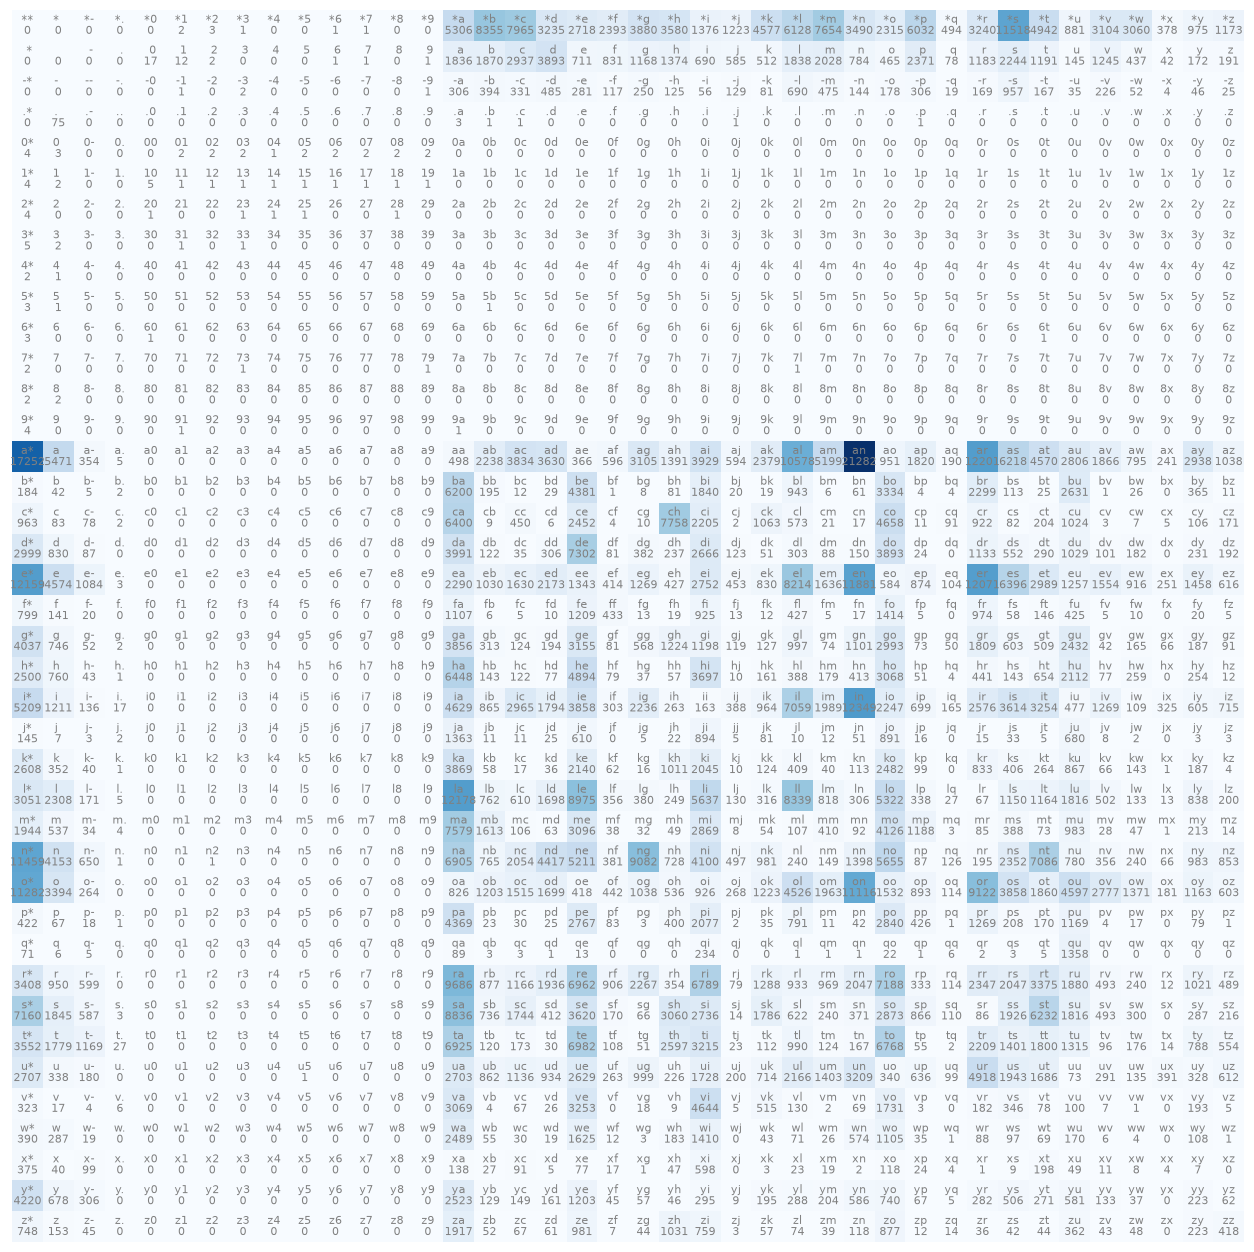

In [19]:
import matplotlib.pyplot as plt  # Librería estándar para graficar en Python
#%matplotlib inline

plt.figure(figsize=(16, 16))               # Creamos una figura grande (16x16 pulgadas)
plt.imshow(bigram_count, cmap='Blues')     # Dibujamos la matriz como MAPA DE CALOR (más azul = más conteos)
for i in range(len(charset)):              # Recorremos las filas
    for j in range(len(charset)):          # Recorremos las columnas
        chars = itoc[i] + itoc[j]          # Reconstruimos el bigrama (ej: 'ab') para mostrarlo como texto
        # Escribimos el bigrama arriba y su conteo abajo, dentro de cada celda
        plt.text(j, i, chars, ha='center', va='bottom', color='grey', fontsize=8)
        plt.text(j, i, bigram_count[i, j], ha='center', va='top', color='grey', fontsize=8)
plt.axis('off')                            # Ocultamos los ejes para que se vea más limpio

## Convertir la matriz de cuentas en una matriz de probabilidades

Ahora armamos la distribucion de probabilidad en base a la primer fila

In [20]:
# Tomamos la primera fila de la matriz (fila de '*'): los conteos de qué caracter viene
# DESPUÉS del inicio de palabra, es decir, con qué caracter empiezan las palabras.
p = bigram_count[0]
# Normalizamos: dividimos por la suma total para convertir conteos en una
# DISTRIBUCIÓN DE PROBABILIDAD (todos los valores entre 0 y 1, y en total suman 1).
p = p / p.sum()
p

array([0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
       2.0000e-05, 3.0000e-05, 1.0000e-05, 0.0000e+00, 0.0000e+00,
       1.0000e-05, 1.0000e-05, 0.0000e+00, 0.0000e+00, 5.3060e-02,
       8.3550e-02, 7.9650e-02, 3.2350e-02, 2.7180e-02, 2.3930e-02,
       3.8800e-02, 3.5800e-02, 1.3760e-02, 1.2230e-02, 4.5770e-02,
       6.1280e-02, 7.6540e-02, 3.4900e-02, 2.3150e-02, 6.0320e-02,
       4.9400e-03, 3.2400e-02, 1.1518e-01, 4.9420e-02, 8.8100e-03,
       3.1040e-02, 3.0600e-02, 3.7800e-03, 9.7500e-03, 1.1730e-02])

In [21]:
# Elegimos un caracter al azar RESPETANDO la distribución de probabilidad p.
# Los caracteres más frecuentes como inicio de palabra tienen más chances de salir sorteados.
np.random.choice(charset, p=p)

np.str_('c')

Hacemos una funcion que nos genera nombre de ciudades

In [22]:
def generate(bigram_count):
    new = []                          # Acá vamos a ir guardando los caracteres que generemos
    p = bigram_count[0]               # Distribución del caracter inicial (fila de '*')
    p = p / p.sum()                   # Normalizamos a probabilidades (suma 1)
    draw = np.random.choice(charset, 1, p=p, replace=True)[0]  # Sorteamos el PRIMER caracter
    while draw != '*':                # Seguimos hasta sortear '*' (que marca el FIN de la palabra)
        p = bigram_count[ctoi[draw]]  # Fila del caracter actual: distribución del SIGUIENTE caracter
        p = p / p.sum()               # Normalizamos esa fila a probabilidades
        #p = [1/40]*40                # (alternativa: distribución uniforme = modelo que elige totalmente al azar)
        draw = np.random.choice(charset, 1, p=p, replace=True)[0]  # Sorteamos el siguiente caracter
        new.append(draw)              # Lo agregamos a la palabra que estamos construyendo
    return ''.join(new[:-1])          # Unimos los caracteres (sin el '*' final) y devolvemos el nombre generado

In [23]:
# Generamos 10 nombres de ciudades usando el modelo (matriz de conteos)
for i in range(10):
    print(generate(bigram_count))

avildaplon ntziengh
ho cori
o
rinogadagu de bangam

ia
nountsololertha
edlilanipuc
tarelukonohtie
icanzen-desur


In [24]:
# Generamos otros 10 nombres. Como el proceso es aleatorio, salen distintos en cada corrida.
for i in range(10):
    print(generate(bigram_count))

euroningr
khrres-la
erenclmbrerneshorievathoje valdon ja
acalor
-mondu
usan sen
jatatotomard
osainana
a wialantelel
toucht


## Convertir la matriz de cuentas en una matriz de probabilidades

In [25]:
# Convertimos TODA la matriz de conteos en una matriz de PROBABILIDADES de una sola vez (vectorizado).
# bigram_count.sum(axis=1, keepdims=True) suma cada FILA y mantiene la forma de columna para poder dividir.
# Resultado: cada fila queda normalizada -> dado un caracter (fila), sus probabilidades suman 1.
bigram_prob = bigram_count / bigram_count.sum(axis=1, keepdims=True)
bigram_prob

array([[0.        , 0.        , 0.        , ..., 0.00378   , 0.00975   ,
        0.01173   ],
       [0.        , 0.        , 0.        , ..., 0.00136121, 0.00557446,
        0.00619024],
       [0.        , 0.        , 0.        , ..., 0.00066094, 0.00760079,
        0.00413087],
       ...,
       [0.18796992, 0.02005013, 0.04962406, ..., 0.00200501, 0.00350877,
        0.        ],
       [0.30140704, 0.04842511, 0.02185558, ..., 0.        , 0.01592743,
        0.00442826],
       [0.09039275, 0.01848943, 0.00543807, ..., 0.        , 0.02694864,
        0.0505136 ]], shape=(40, 40))

In [26]:
# Sorteamos el primer caracter de una palabra usando la fila de '*' de la matriz de PROBABILIDADES
# (ya está normalizada, así que no hace falta volver a dividir).
np.random.choice(charset, p=bigram_prob[ctoi['*']])

np.str_('t')

## La Negative Log Likelihood loss (NLL loss)

### 📐 ¿Cómo medimos si el modelo es bueno?

Queremos ponerle un **número** a "qué tan bien" el modelo explica los datos reales.

**1. Likelihood (verosimilitud).** Para una palabra, multiplicamos las probabilidades que el modelo le asigna a cada bigrama:

$$ \text{Likelihood} = \prod_{i} P(c_{i+1} \mid c_i) $$

Si el modelo es bueno, le da probabilidad alta a los bigramas que realmente ocurren, y este producto es grande.

**2. Log-likelihood.** Multiplicar muchas probabilidades (números entre 0 y 1) da valores diminutos y difíciles de manejar. Aplicamos **logaritmo**, que convierte el producto en una **suma** (más estable numéricamente):

$$ \log(\text{Likelihood}) = \sum_{i} \log P(c_{i+1} \mid c_i) $$

**3. Negative Log-Likelihood (NLL).** El log de un número entre 0 y 1 es negativo. Para trabajar con un valor **positivo que queremos minimizar**, le cambiamos el signo y lo promediamos por la cantidad de bigramas $n$:

$$ \text{NLL} = -\frac{1}{n} \sum_{i} \log P(c_{i+1} \mid c_i) $$

- **NLL bajo** → el modelo predice bien (le da alta probabilidad a lo que ocurre). ✅
- **NLL alto** → el modelo predice mal. ❌
- Un modelo que elige **al azar** entre 40 caracteres tiene NLL ≈ $-\log(1/40) \approx 3.69$. ¡Nuestro modelo debería dar más bajo que eso!

Vamos a ver que tan bueno es el modelo

In [27]:
1 / len(charset)          # Probabilidad de acertar un caracter eligiéndolo COMPLETAMENTE al azar (1 entre 40)
# -log(prob) es la "pérdida" asociada a esa probabilidad. Este es el peor caso de referencia:
# un modelo que adivina al azar. La idea es MINIMIZAR esta pérdida (L).
# Sería 0 si el modelo predijera el siguiente caracter con probabilidad 1, pero eso es imposible
# porque siempre hay más de un caracter posible con probabilidad mayor que 0.
-np.log(1 / len(charset))

np.float64(3.6888794541139363)

In [28]:
def nll(s: list[str]) -> float:
    """Negative Log Likelihood: mide qué tan 'sorprendido' está el modelo por los datos. Más bajo = mejor."""
    log_likehood = 0                        # Acumulador de la suma de log-probabilidades
    n = 0                                   # Contador de cuántos bigramas evaluamos
    for d in s:                             # Para cada palabra de la lista de entrada
        example = ['*'] + list(d) + ['*']   # Agregamos marcadores de inicio y fin
        for c1, c2 in zip(example, example[1:]):
            n += 1
            prob = bigram_prob[ctoi[c1], ctoi[c2]]  # Probabilidad que el modelo le asigna a este bigrama
            log_likehood += np.log(prob)            # Sumamos el logaritmo de esa probabilidad
    return -log_likehood / n                # Negamos y promediamos: esta es la pérdida final (NLL)

In [29]:
# Probamos la pérdida con una palabra inventada y sin sentido:
# debería dar un valor ALTO (el modelo la encuentra poco probable / "rara").
nll(['ajsajsjkaskjdq'])

C:\Users\famil\AppData\Local\Temp\ipykernel_5052\1328940591.py:10: RuntimeWarning: divide by zero encountered in log
  log_likehood += np.log(prob)            # Sumamos el logaritmo de esa probabilidad


np.float64(inf)

Para solucionar si sale algun bigrama con probabilidad cero (Nos daria L -> Inf) hacemos lo siguiente:

## Model Smoothing

Hacemos que todas tengan al menos una vez una ocurrencia

In [30]:
# "Model smoothing" (suavizado): le sumamos 1 a TODOS los conteos.
# Así ningún bigrama queda en 0. Esto evita probabilidades de 0, que harían que
# log(0) = -infinito y, por lo tanto, que la pérdida NLL se volviera infinita.
bigram_count += 1
bigram_count

array([[   1,    1,    1, ...,  379,  976, 1174],
       [   1,    1,    1, ...,   43,  173,  192],
       [   1,    1,    1, ...,    5,   47,   26],
       ...,
       [ 376,   41,  100, ...,    5,    8,    1],
       [4221,  679,  307, ...,    1,  224,   63],
       [ 749,  154,   46, ...,    1,  224,  419]], shape=(40, 40))

In [31]:
# Recalculamos las probabilidades ahora que ya aplicamos el suavizado (ningún valor es 0).
bigram_prob = bigram_count / bigram_count.sum(axis=1, keepdims=True)
bigram_prob

array([[9.99600160e-06, 9.99600160e-06, 9.99600160e-06, ...,
        3.78848461e-03, 9.75609756e-03, 1.17353059e-02],
       [3.23676970e-05, 3.23676970e-05, 3.23676970e-05, ...,
        1.39181097e-03, 5.59961159e-03, 6.21459783e-03],
       [1.64149705e-04, 1.64149705e-04, 1.64149705e-04, ...,
        8.20748523e-04, 7.71503611e-03, 4.26789232e-03],
       ...,
       [1.84766585e-01, 2.01474201e-02, 4.91400491e-02, ...,
        2.45700246e-03, 3.93120393e-03, 4.91400491e-04],
       [3.00619614e-01, 4.83583790e-02, 2.18645396e-02, ...,
        7.12199986e-05, 1.59532797e-02, 4.48685991e-03],
       [9.00781720e-02, 1.85207456e-02, 5.53217078e-03, ...,
        1.20264582e-04, 2.69392664e-02, 5.03908599e-02]], shape=(40, 40))

## Sampleando del modelo

In [32]:
def generate(bigram_count):
    new = []
    p = bigram_prob[ctoi['*']]        # Distribución del caracter inicial (ya normalizada, no hace falta dividir)
    draw = np.random.choice(charset, 1, p=p, replace=True)[0]  # Sorteamos el primer caracter
    while draw != '*':                # Hasta llegar al marcador de FIN de palabra
        p = bigram_prob[ctoi[draw]]   # Distribución del siguiente caracter, dado el actual
        draw = np.random.choice(charset, 1, p=p, replace=True)[0]
        new.append(draw)
    return ''.join(new[:-1])          # Devolvemos la palabra generada, sin el '*' final

In [33]:
# Generamos 100 nombres con el modelo y medimos su pérdida (NLL) promedio.
# Da MÁS BAJO que el modelo al azar (~3.69), lo que confirma que el modelo efectivamente aprendió patrones.
l = []
for _ in range(100):
    l.append(generate(bigram_prob))
nll(l)

np.float64(2.781585835847528)

Esto no escala a N-gramas

## Conclusiones
* En este módulo creamos un modelo de bigramas probabilistico autoregresivo.
* El modelo cuenta las ocurrencias de los bigramas y luego calcula las distribuciones de probabilidad de un carácter dado el carácter anterior.
* Toda la información está contenida en una matriz de probabilidades
* Vimos como calcular que tan bueno o malo es el modelo respecto a nuestro universo de carácteres conocidos (charset) y a un modelo que elige carácteres al azar.
* Esta métrica nos va a acompañar el resto del curso y vamos a volver sobre esto luego.

## Ejercicios
* Generar un modelo de trigramas (intermedio).
  * Pista: En lugar de una matriz, guardar las probabilidades en un tensor tridimensional.

## 🔌 Del conteo a las redes neuronales: One-Hot Encoding

Hasta acá "entrenamos" el modelo **contando**. El siguiente paso (que se desarrolla en el notebook de redes neuronales) es que una **red neuronal aprenda** esas probabilidades por su cuenta.

Pero una red neuronal no entiende de letras: solo trabaja con **números**. ¿Cómo le pasamos un caracter? Con **one-hot encoding**:

- Cada caracter se representa con un vector del tamaño del vocabulario (40).
- Ese vector es todo **ceros**, excepto un único **1** en la posición del caracter.
- Ejemplo (si `'a'` es el índice 14): `'a'` → `[0, 0, ..., 1, ..., 0]` (el 1 está en la posición 14).

¿Por qué no pasar directamente el índice (ej. `14`)? Porque la red interpretaría esos números como cantidades con orden y magnitud (que `25` es "más" que `14`), y los caracteres no tienen ese orden. El one-hot los trata a todos como categorías independientes.

Abajo preparamos los datos y **visualizamos** este encoding como imagen.

In [34]:
import torch  # PyTorch: librería para redes neuronales y cálculo eficiente con tensores

In [35]:
# Preparamos los datos para el enfoque de RED NEURONAL (en lugar de solo contar).
# xs = entradas  (caracter actual)    -> como ÍNDICES numéricos
# ys = objetivos (caracter siguiente) -> como ÍNDICES numéricos
xs, ys = [], []
for d in dataset[3:4]:                      # Usamos solo 1 nombre de ejemplo (dataset[3:4])
    example = ['*'] + list(d) + ['*']
    for c1, c2 in zip(example, example[1:]):
        xs.append(ctoi[c1])                 # Índice del caracter actual
        ys.append(ctoi[c2])                 # Índice del caracter siguiente
xs = torch.tensor(xs)                       # Convertimos la lista de Python a un tensor de PyTorch
ys = torch.tensor(ys)

In [36]:
xs.shape  # Forma del tensor: cuántos bigramas (ejemplos) tenemos en esta palabra

torch.Size([6])

In [37]:
import torch.nn.functional as F  # Funciones auxiliares de PyTorch; acá usamos one_hot

In [38]:
# one_hot convierte cada índice en un vector de 0s con un único 1 en la posición del caracter.
# num_classes = tamaño del vocabulario -> cada vector tiene esa longitud (40).
# .float() lo pasa a números flotantes. .shape nos muestra la forma: (cantidad de ejemplos, tamaño del vocabulario).
F.one_hot(xs, num_classes=len(charset)).float().shape

torch.Size([6, 40])

In [ ]:
# Número de clases = tamaño de nuestro vocabulario (cantidad de caracteres distintos, incluyendo '*').
nclasses = len(charset)

# Hacemos el one-hot encoding de las entradas xs.
# F.one_hot convierte cada índice en un vector de ceros con un único 1 en la posición del caracter.
# .float() convierte el tensor de enteros (int64) a flotantes (float32), que es el tipo que
# necesitan tanto matplotlib para dibujar como las redes neuronales para operar.
xenc = F.one_hot(xs, num_classes=nclasses).float()

xenc  # Mostramos el tensor one-hot: una matriz de 0s y 1s (filas = caracteres, columnas = vocabulario)

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,

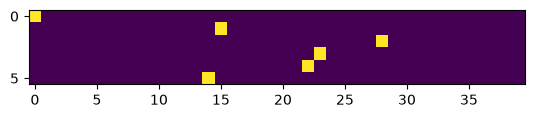

In [40]:
# Visualizamos el tensor one-hot como imagen.
# Cada FILA es un caracter de la secuencia y cada COLUMNA una posición del vocabulario.
# La casilla encendida (valor 1) indica qué caracter es; el resto de la fila son 0.
plt.imshow(xenc)

In [41]:
itoc[14]

'a'

## Primer intento - Una "red neuronal" de una neurona

### 🧠 ¿Qué es una neurona artificial?

Una **neurona** es la unidad mínima de una red neuronal. Está inspirada (muy libremente) en una neurona biológica y hace 4 cosas:

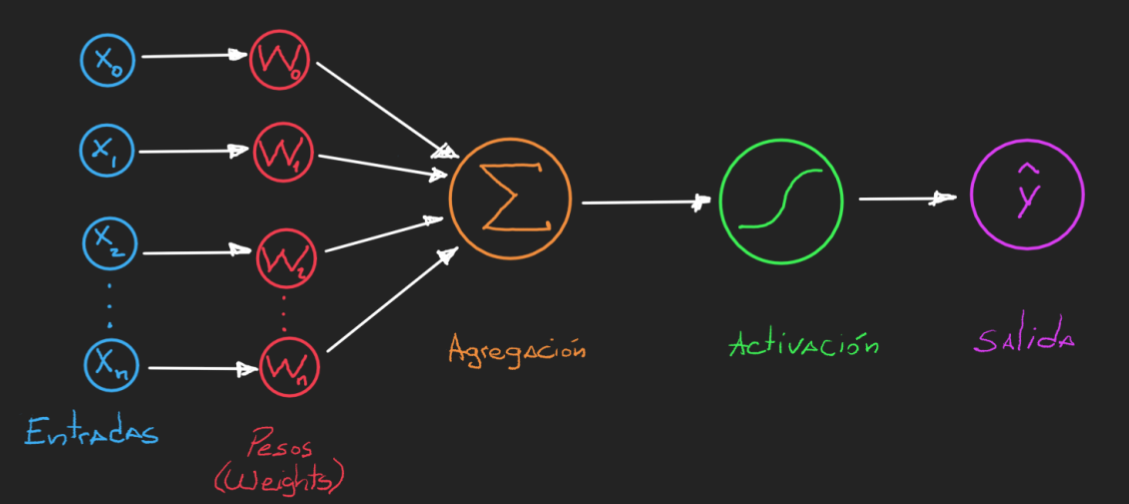

1. **Entradas** ($x_0, x_1, \dots, x_n$): los números que recibe. En nuestro caso, el caracter actual codificado en *one-hot*.
2. **Pesos** ($w_0, w_1, \dots, w_n$): un número por cada entrada. Son los **parámetros que la red aprende**: indican cuánta importancia le da la neurona a cada entrada.
3. **Agregación** ($\Sigma$): multiplica cada entrada por su peso y los **suma**:
$$ z = \sum_{i=0}^{n} w_i \, x_i \; (+\, b) $$
   (opcionalmente se suma un término extra $b$ llamado *bias* o sesgo).
4. **Activación**: una función no lineal (sigmoide, ReLU, etc.) que deforma $z$ para darle a la neurona capacidad de aprender relaciones no lineales. Su resultado es la **salida** $\hat{y}$.

### Nuestra primera versión: una neurona LINEAL, sin bias ni activación

Para empezar lo más simple posible, quitamos el *bias* y la *activación*. Nos quedamos solo con **pesos + agregación**:

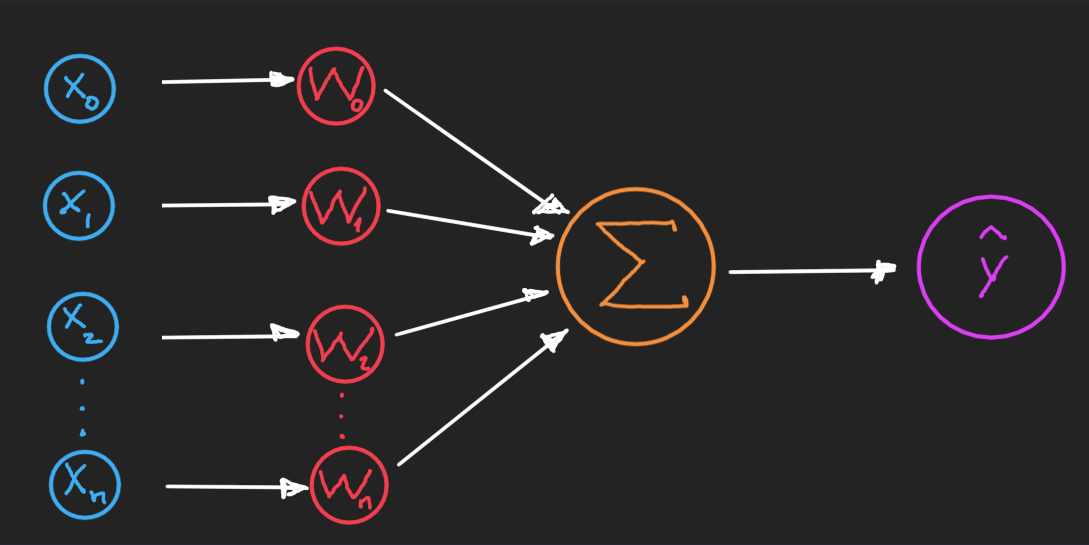

$$ \hat{y} = \sum_{i=0}^{39} w_i \, x_i = X \cdot W $$

La entrada es un vector **one-hot** de 40 dimensiones (39 ceros y un único 1):
$$ X = (x_0, x_1, \dots, x_{39}), \quad x_i \in \{0, 1\} $$
donde el único 1 está en el índice de la letra de entrada.

> 💡 **Truco clave del one-hot:** como $X$ es todo ceros menos un 1 en la posición $k$, el producto $X \cdot W$ **selecciona directamente el peso $w_k$** (los demás se multiplican por 0 y desaparecen). Multiplicar por un vector one-hot equivale a "ir a buscar" la fila $k$ de la matriz de pesos.

La matriz de pesos `W` tendrá forma `(40, 1)`: **40 entradas → 1 sola salida** (una única neurona).


In [50]:
# Generador de números aleatorios con semilla fija (42): así los pesos iniciales
# son SIEMPRE los mismos y los resultados son reproducibles.
g = torch.Generator().manual_seed(42)

# W = pesos de nuestra ÚNICA neurona. Matriz (40, 1):
#   - 40 filas    -> un peso por cada entrada (tamaño del vocabulario)
#   -  1 columna  -> una sola neurona = una sola salida
# torch.randn los inicializa al azar (distribución normal).
# requires_grad=True -> PyTorch calculará el gradiente de W (lo necesitamos para entrenar).
W = torch.randn((nclasses, 1), generator=g, requires_grad=True)

# Forward pass: (6, 40) @ (40, 1) = (6, 1)  -> UN número de salida por cada bigrama.
# Como la entrada es one-hot, cada resultado es simplemente el peso de la letra activa.
xenc @ W


tensor([[ 1.9269],
        [ 0.7624],
        [ 1.3123],
        [ 1.6806],
        [ 0.8008],
        [-0.7688]], grad_fn=<MmBackward0>)

In [49]:
# Antes de llamar a loss.backward(), W todavía no tiene gradientes calculados:
# W.grad es None. PyTorch recién lo completa DESPUÉS del backward pass.
W.grad


## ❌ ¿Por qué este primer intento NO funciona?

Mirá el dibujo de nuestra neurona lineal: termina en **una sola salida** $\hat{y}$. Ese es exactamente el problema.

**El problema de fondo:** para predecir el siguiente caracter necesitamos una **probabilidad para cada uno de los 40 caracteres posibles**. Es decir, necesitamos **40 números** de salida. Pero una sola neurona produce **un único número**.

Veámoslo con el ejemplo `bojia` (`dataset[3:4]`):

- `xenc @ W` tiene forma **(6, 1)**: un número por bigrama, no 40.
- Si intentamos convertir ese único número en una distribución con *softmax*, como hay **un solo valor por fila**, el softmax da **1.0 siempre** (el softmax de un vector de un elemento es trivialmente 1). La "distribución" es **degenerada**.
- Al tomar el `argmax`, la predicción es **siempre la clase 0** (`'*'`), sin importar cuál sea la letra de entrada → **predice siempre lo mismo**.
- Y si la **entrenamos** (repartiendo su única salida entre las 40 clases, que es lo máximo que puede hacer), todas las clases reciben el mismo número → el softmax da la **distribución uniforme** $1/40$ para *cualquier* entrada. La pérdida queda **clavada en** $-\log(1/40) \approx 3.6889$ (idéntica a elegir al azar) y el **gradiente es 0**: no hay absolutamente nada que aprender.

> 🔑 **Conclusión:** una neurona (1 salida) no puede representar una distribución sobre 40 caracteres. Necesitamos **40 neuronas** (40 salidas, una por cada caracter posible). Eso será el *segundo intento*.

Abajo comprobamos todo esto con `bojia`.


### 🔬 Comprobación con el ejemplo `bojia`

`xs`, `ys` y `xenc` ya fueron construidos más arriba a partir de `dataset[3:4]` = `['bojia']`.
Los 6 bigramas de `*bojia*` son: `(*,b) (b,o) (o,j) (j,i) (i,a) (a,*)`.


In [ ]:
# --- Forward de la neurona única sobre 'bojia' y por qué su salida es inservible ---

# Pesos de la ÚNICA neurona: 40 entradas -> 1 salida.
g = torch.Generator().manual_seed(42)
W = torch.randn((nclasses, 1), generator=g, requires_grad=True)

# Forward: (6, 40) @ (40, 1) = (6, 1)  -> un solo número por bigrama.
logits = xenc @ W
print('Forma de la salida:', logits.shape, '-> 1 numero por bigrama (necesitariamos 40)')

# Intentamos interpretarla como probabilidades con softmax.
# Como cada fila tiene UN solo valor, el softmax de un unico elemento es siempre 1.0.
probs = logits.exp() / logits.exp().sum(axis=1, keepdims=True)
print('Softmax (degenerado, todo 1.0):', [round(p, 3) for p in probs.detach().squeeze().tolist()])

# La prediccion (argmax) es SIEMPRE la clase 0 ('*'), sin importar la entrada:
pred = probs.argmax(axis=1)
print('Prediccion por bigrama:', [itoc[i.item()] for i in pred], '<- siempre el mismo caracter')


Forma de la salida: torch.Size([6, 1]) -> 1 numero por bigrama (necesitariamos 40)
Softmax (degenerado, todo 1.0): [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
Prediccion por bigrama: ['*', '*', '*', '*', '*', '*'] <- siempre el mismo caracter


In [ ]:
# --- ¿Y si la ENTRENAMOS? Demostramos que no puede aprender ---
# Para comparar su única salida contra las 40 clases, repartimos ese único número
# entre las 40 columnas (lo repetimos con .expand). Es lo máximo que puede hacer una
# sola neurona: darle el MISMO puntaje a todos los caracteres posibles.
g = torch.Generator().manual_seed(42)
W = torch.randn((nclasses, 1), generator=g, requires_grad=True)

for k in range(100):
    logits = xenc @ W                        # (6, 1): una salida por bigrama
    logits40 = logits.expand(-1, nclasses)   # (6, 40): el MISMO número repetido en las 40 clases
    counts = logits40.exp()
    probs = counts / counts.sum(axis=1, keepdims=True)    # softmax
    loss = -probs[range(len(ys)), ys].log().mean()        # NLL
    W.grad = None
    loss.backward()
    W.data += -50 * W.grad                    # paso de descenso por gradiente

print('Loss tras 100 pasos:', round(loss.item(), 4))
print('Baseline al azar -log(1/40):', round(float(-np.log(1 / nclasses)), 4))
print('Probabilidades (uniformes 1/40):', [round(p, 3) for p in probs[0].detach().tolist()[:5]], '...')
# La loss queda clavada en ~3.6889 (igual que elegir al azar) y NO baja nunca:
# todas las clases reciben el mismo puntaje -> softmax uniforme -> gradiente nulo.
# => Una sola neurona NO puede aprender a predecir. Necesitamos 40 neuronas.


Loss tras 100 pasos: 3.6889
Baseline al azar -log(1/40): 3.6889
Probabilidades (uniformes 1/40): [0.025, 0.025, 0.025, 0.025, 0.025] ...


➡️ Como vimos, **una neurona no alcanza**: solo produce un número y por eso predice siempre lo mismo. Necesitamos **una salida por cada caracter posible** (40 *logits*), es decir, una **capa de 40 neuronas**. Eso construimos a continuación.


## Segundo intento - Una red con una capa de 40 neuronas
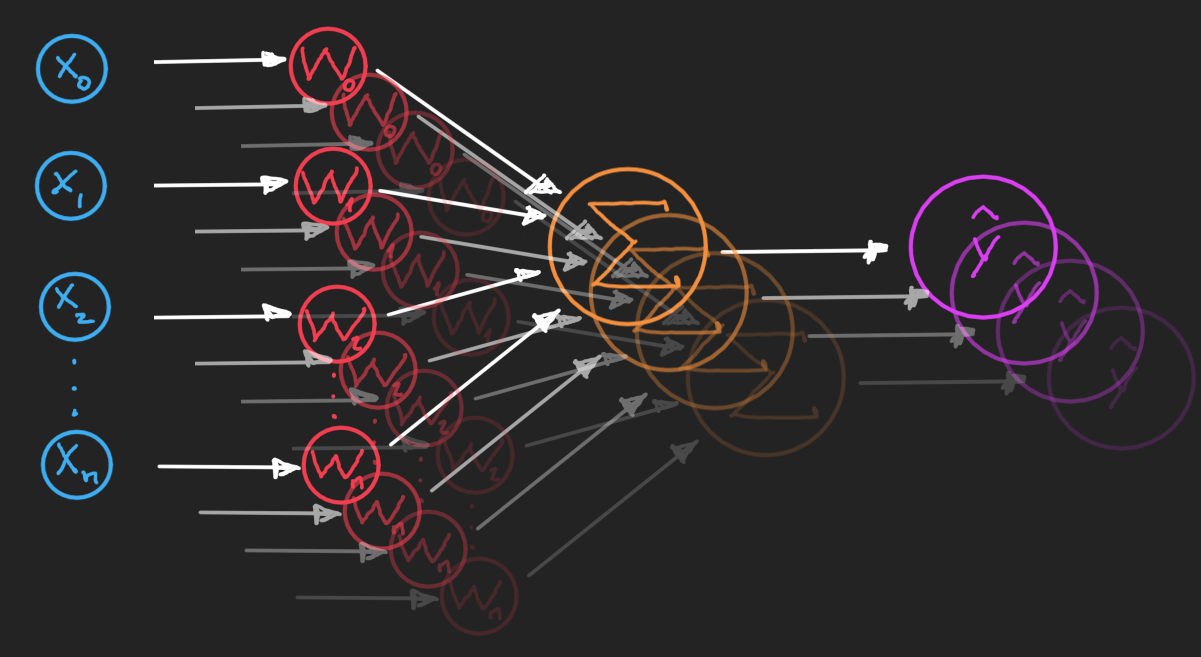

Ahora usamos **40 neuronas** (una por cada caracter posible del vocabulario). Cada neurona recibe las mismas 40 entradas one-hot, así que los pesos forman una matriz `W` de forma **(40, 40)**:

- La **columna $j$** son los 40 pesos de la neurona $j$ (la que puntúa al caracter $j$ como "siguiente").
- `xenc @ W` ahora da **(n, 40)**: para cada bigrama, **40 números** (uno por caracter candidato). Esos números se llaman *logits*.

Como la entrada es one-hot, cada fila de la salida es simplemente la **fila de `W`** del caracter de entrada: la red aprende, en cada fila, la distribución del siguiente caracter (igual que la matriz de conteos del principio, ¡pero aprendida con gradientes!).


In [52]:
# Reinicializamos los pesos, ahora como matriz (40, 40) = 40 neuronas de 40 entradas cada una.
g = torch.Generator().manual_seed(42)
W = torch.randn((nclasses, nclasses), generator=g, requires_grad=True)
W.shape
# Forward: (n, 40) @ (40, 40) = (n, 40). Ahora SÍ tenemos 40 salidas (logits) por bigrama.
xenc @ W


tensor([[ 1.9269e+00,  1.4873e+00,  9.0072e-01, -2.1055e+00,  6.7842e-01,
         -1.2345e+00, -4.3067e-02, -1.6047e+00, -7.5214e-01,  1.6487e+00,
         -3.9248e-01, -1.4036e+00, -7.2788e-01, -5.5943e-01, -7.6884e-01,
          7.6245e-01,  1.6423e+00, -1.5960e-01, -4.9740e-01,  4.3959e-01,
         -7.5813e-01,  1.0783e+00,  8.0080e-01,  1.6806e+00,  1.2791e+00,
          1.2964e+00,  6.1047e-01,  1.3347e+00, -2.3162e-01,  4.1759e-02,
         -2.5158e-01,  8.5986e-01, -1.3847e+00, -8.7124e-01, -2.2337e-01,
          1.7174e+00,  3.1888e-01, -4.2452e-01,  3.0572e-01, -7.7459e-01],
        [ 4.9816e-01, -1.2000e+00,  1.2711e-01,  4.4037e-01,  6.3777e-01,
          1.5979e-01,  1.7698e+00,  6.2682e-01, -1.8737e+00,  2.3259e+00,
         -9.2039e-01,  6.6611e-01, -4.4026e-01, -2.3180e+00,  1.2946e+00,
          2.2267e-01, -8.4834e-01,  1.6489e+00,  1.6006e+00, -7.8589e-02,
          4.3105e-01,  3.6835e-01,  7.6380e-01,  1.1792e+00, -4.1379e-01,
          5.1841e-01, -7.0154e-01, -4

## Como interpretar la salida de la red?
La pregunta es que es esto 👆 Cómo interpretamos el output de la red neuronal?
* No son probabilidades porque exceden el rango [0, 1]
* No son counts por que son flotantes y hay negativos

Vamos a interpretar esta salida como log(counts) o logits. Para obtener counts podemos exponenciar. Luego, si normalizamos podemos interpretar la salida como probabilidades.

In [55]:
# plt.plot(np.arange(0.001, 5, 0.01),np.log(np.arange(0.001, 5,0.01)));plt.grid()

In [56]:
# plt.plot(np.arange(-4, 2, 0.01),np.exp(np.arange(-4, 2,0.01)));plt.grid()

In [ ]:
# Desglosamos el cálculo de la pérdida (NLL) bigrama por bigrama del ejemplo 'bojia',
# para VER qué probabilidad le asigna la red al caracter correcto en cada paso.
logits = (xenc @ W)
counts = logits.exp()
probs = counts / counts.sum(axis=1, keepdims=True)   # softmax -> distribución por fila

nlls = torch.zeros(len(ys))
for i in range(len(ys)):              # un solo bucle (antes había uno anidado de más, un bug)
    x = xs[i].item()                  # índice del caracter de entrada
    y = ys[i].item()                  # índice del caracter correcto (la etiqueta)
    print('--------------')
    print(f'Bigrama {i}: ({itoc[x]}, {itoc[y]}) idx:({x},{y})')
    print(f'Entrada: {x}')
    print(f'Salida (probs): {probs[i]}')
    p = probs[i, y]                   # probabilidad que la red le dio al caracter correcto
    print(f'Probabilidad asignada a la etiqueta {y}: {p.item()}')
    logp = torch.log(p)
    print(f'Log Likelihood: {logp.item()}')
    nll = -logp                       # negative log likelihood de este bigrama
    nlls[i] = nll
    print(f'Negative Log Likelihood: {nll.item()}')
print('============')
print(f'NLL promedio (loss): {nlls.mean().item()}')   # promedio de los 6 = pérdida final


## Pasando en limpio
## La función de perdida vectorizada (vectorized loss)

In [63]:
xs, ys = [], []

for d in dataset:
    example = ['*'] + list(d) + ['*']
    for c1, c2 in zip(example, example[1:]):
        xs.append(ctoi[c1])
        ys.append(ctoi[c2])
       # print(c1, c2)
xs = torch.tensor(xs)
ys = torch.tensor(ys)

In [74]:
# forward pass
xenc = F.one_hot(xs,num_classes=nclasses).float()  # la entrada a la NN en encodeada en one_hot
logits = xenc @ W  # hacemos una predicción de los log(counts)
counts = logits.exp()                               # obtenemos la matriz de cuentas        `|__
probs = counts / counts.sum(axis=1, keepdims=True)  # obtenemos la matriz de probabilidades ,|   Esto es lo que se conoce como softmax


loss = -probs[range(len(ys)), ys].log().mean()
loss

tensor(4.1624, grad_fn=<NegBackward0>)

## La función Softmax
La función softmax toma un vector de logits $Z$ y aplica la siguiente función a cada uno de sus valores $z_i$:

$$softmax(Z) = \frac{e^{z_i}}{\sum_j^k e^{z_j}}$$

La función softmax (en forma de capas de torch) es muy utilizada. Básicamente convierte la salida de una red neuronal en una distribución de probabilidad (ojo, que estoy abusando del lenguaje). Para ser estrictos, softmax toma el vector de salidas de la red neuronal y retorna un vector de igual dimensión, normalizado al rango `[0, 1]`.

In [65]:
loss.backward()

In [66]:
W.grad.shape

torch.Size([40, 40])

In [73]:
W.data -= W.grad * 0.1

## Entrenamos el modelo

In [75]:
# Preparamos los datos con TODO el dataset (no solo 'bojia'): construimos las entradas
# xs (caracter actual) y las etiquetas ys (caracter siguiente), como índices.
xs, ys = [], []
for d in dataset:
    example = ['*'] + list(d) + ['*']
    for c1, c2 in zip(example, example[1:]):
        xs.append(ctoi[c1])
        ys.append(ctoi[c2])
        # print(c1, c2)
xs = torch.tensor(xs)
ys = torch.tensor(ys)
nsamples = xs.nelement()                 # cantidad total de bigramas (para promediar la loss)
# Inicializamos los pesos de la capa de 40 neuronas.
g = torch.Generator().manual_seed(42)
W = torch.randn((nclasses, nclasses), generator=g, requires_grad=True)


In [ ]:
# Bucle de entrenamiento (descenso por gradiente).
iterations = 100   # subimos las iteraciones (antes 10 no alcanzaban para aprender)
lr = 50            # learning rate alto: el gradiente del one-hot es chico, necesita pasos grandes
print('Cantidad de bigramas:', nsamples)
for k in range(iterations):
    # --- forward pass ---
    xenc = F.one_hot(xs, num_classes=nclasses).float()   # entrada en one-hot: (n, 40)
    logits = xenc @ W                                    # log(counts) predichos: (n, 40)
    # --- loss (softmax + NLL) ---
    counts = logits.exp()                                # exponenciamos -> "cuentas"
    probs = counts / counts.sum(axis=1, keepdims=True)   # normalizamos -> probabilidades (softmax)
    loss = -probs[range(nsamples), ys].log().mean()      # NLL promedio sobre la etiqueta correcta
    # --- backward pass ---
    W.grad = None                                        # ponemos los gradientes en cero
    loss.backward()                                      # PyTorch calcula dloss/dW
    # --- update ---
    W.data += -lr * W.grad                               # movemos W en contra del gradiente

print('Loss final:', loss.item())   # debería bajar bien por debajo de 3.6889 (baseline al azar)


## Regularization loss como análogo del model smoothing


In [80]:
-np.log(1/40)

np.float64(3.6888794541139363)

In [81]:
(W**2).mean()

tensor(0.9779, grad_fn=<MeanBackward0>)

In [ ]:
# Sampleamos 10 nombres del modelo entrenado, de a un caracter por vez (autoregresivo).
g = torch.Generator().manual_seed(42)
for i in range(10):
    out = []
    ix = 0                                    # empezamos en '*' (índice 0 = inicio de palabra)
    while True:
        xenc = F.one_hot(torch.tensor([ix]), num_classes=nclasses).float()  # one-hot del caracter actual
        logits = xenc @ W                                                   # logits de los 40 siguientes
        counts = logits.exp()
        probs = counts / counts.sum(axis=1, keepdims=True)                  # softmax -> distribución
        ix = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()  # sorteamos el siguiente
        out.append(itoc[ix])
        if ix == 0:                           # si sorteamos '*', terminó la palabra
            break
    print(''.join(out[:-1]))                  # imprimimos la palabra completa (sin el '*' final)
